# 9. One Rule

> **Overview.** Error times explained fraction weighs an output's error by how much of it the network has explained,
> which noisy linear outputs fool. Is there one rule, with no hyperparameters, that weighs the error by evidence from
> the LTUs themselves instead, and is as good everywhere else?

**Setup.** Notebook 4's target and learner, with the other 90 outputs noise or noisy linear, and notebook 7's moving
needle (with noise outputs). Every rule draws parents in proportion to an output's error $L_o$ times something. 5
seeds; 500k steps.
- **9a.** Times explained fraction, $(V_o - L_o)/V_o$ (notebook 4a).
- **9b.** Times the fraction of the error without the LTUs' part that they remove, $R_o/(L_o + R_o)$, with $R_o$ the
  squared error they remove (notebook 3).
- **9c.** Times credited progress, the increase in $R_o$ since the last search period.
- **9d.** Times credited progress averaged over 8 periods, the time search takes to replace as many LTUs as there are.

Against parents drawn uniformly, and by an oracle (among the first 10; for the needle, the needle).

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 100
N_IMPROVABLE = 10                    # the first outputs, each reading target LTUs at first
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STD = 0.1                      # observation noise on outputs that read target LTUs: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE on such an output
N_CHANGES = 8                        # changes (needle problem), one output at a time, alternating: an output changes;
FIRST_CHANGE, CHANGE_EVERY = 100_000, 50_000   # a noise output becomes a target (and an improvable output noise)
N_NEW = 2                            # new target LTUs the changed output reads
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size (the inputs' weights to the outputs: per run)
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, EXPLAINED, MIXED, LTU_EXPLAINED, ERR_PROGRESS, ORACLE = range(6)   # how a new LTU's parent is drawn
EXPLAINED_SHARE = 0.5                # share of the new LTUs drawn by error times explained fraction, if MIXED
NOISE, NOISY_LINEAR = 0, 2           # kinds of the outputs that do not read target LTUs

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, N_OUTPUTS, N_ALL_TARGETS): the outputs' weights on them, by version
    noise_std: jax.Array        # (N_CHANGES + 1, N_OUTPUTS): each output's noise, by version
    needle: jax.Array           # (N_CHANGES + 1,): the newest output reading new target LTUs (-1 before any change)
    linear: jax.Array           # (N_OUTPUTS, N_INPUTS): the other outputs' linear weights, if noisy linear


def make_target(key, kind):
    # Version 0: the first N_IMPROVABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise NOISE_STD; the others are noise of unit
    # variance, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs with random +-1 weights
    # scaled to unit variance. Each target LTU reads N_SOURCES inputs drawn at random, with random +-1 weights. Change c makes version
    # c + 1: if c is even, an output reading target LTUs, at random, reads the next N_NEW instead (an output changes);
    # if odd, one of them becomes noise of unit variance, and a noise output, at random, reads the next N_NEW (a noise
    # output becomes a target).
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < N_IMPROVABLE
    reads = jnp.pad(pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    noise_std = jnp.where(first[:, 0], NOISE_STD, 1.0)
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (~first & (kind != NOISE)))
    outs, noise_stds, needles = [out], [noise_std], [jnp.array(-1)]
    for c in range(N_CHANGES):
        sign_key, old_key, new_key = jax.random.split(jax.random.fold_in(change_key, c), 3)
        improvable = (out != 0).any(1)
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        row = jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW)
        old = jax.random.categorical(old_key, jnp.log(improvable))
        if c % 2 == 0:
            needle = old
        else:
            needle = jax.random.categorical(new_key, jnp.log(~improvable))
            out, noise_std = out.at[old].set(0.0), noise_std.at[old].set(1.0)
        out, noise_std = out.at[needle].set(row), noise_std.at[needle].set(NOISE_STD)
        outs, noise_stds, needles = outs + [out], noise_stds + [noise_std], needles + [needle]
    return Target(w, jnp.stack(outs), jnp.stack(noise_stds), jnp.stack(needles), linear)


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear @ x
               + target.noise_std[version] * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

Notebook 7's learner. New here: each output's credited progress averaged over search periods, and the inputs'
weights to the outputs may start at their own step-size.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (N_OUTPUTS,): each output's summed squared error since the last search step
    removed_sum: jax.Array      # (N_OUTPUTS,): the squared error the LTUs removed from each output, summed likewise
    target_sum: jax.Array       # (N_OUTPUTS,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    last_removed: jax.Array     # (N_OUTPUTS,): mean squared error the LTUs removed over the last search period (NaN: none)
    progress: jax.Array         # (N_OUTPUTS,): its credited progress, averaged over search periods


def init_net(key, target):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform weights;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES
    readers = target.out[0][:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)),
               *(jnp.zeros(N_OUTPUTS),) * 4, jnp.full(N_OUTPUTS, jnp.nan), jnp.zeros(N_OUTPUTS))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and each output's squared error on this sample, before learning from it, which it also
    # adds to loss_sum; adds the squared error the LTUs remove from each output (with c their part of the prediction
    # and r the residual, (r - c)^2 - r^2) to removed_sum, the targets and their squares to target_sum and
    # target_sq_sum, and dL/dz * x_i to each LTU's gradient sums. `probe` is zero; its gradients are the error
    # arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        residual = jax.lax.stop_gradient(prediction - y)
        removed = (residual - jax.lax.stop_gradient(unit_w @ a)) ** 2 - residual ** 2
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                      residual ** 2, removed)

    (_, (source, h, mean, squared, removed)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared,
                        removed_sum=net.removed_sum + removed, target_sum=net.target_sum + y,
                        target_sq_sum=net.target_sq_sum + y ** 2), (squared, removed)


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's sum of squared outgoing weights: about the increase in the squared error, summed over the outputs, if
    # it were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def parent_logits(net, rule, needle):
    # Log-probabilities of each output being a new LTU's parent, from its statistics since the last search step, all
    # its squared error L times something: uniform; L times its explained fraction (V - L) / V; MIXED: EXPLAINED_SHARE
    # so, the rest in proportion to its credited progress over the last period; L times the fraction of the error
    # without the LTUs' part that they remove, R / (L + R); L times its averaged credited progress; or the oracle: the
    # needle (uniform among the first N_IMPROVABLE before any change). Negative weights count as 0; each part uniform
    # while all its weights are 0.
    def share(weight):
        weight = jnp.maximum(weight, 0.0)
        return jnp.where(weight.sum() > 0, weight / jnp.maximum(weight.sum(), 1e-30), 1 / N_OUTPUTS)

    loss = net.loss_sum / PERIOD
    variance = net.target_sq_sum / PERIOD - (net.target_sum / PERIOD) ** 2
    removed = jnp.maximum(net.removed_sum / PERIOD, 0.0)
    explained = share(loss * (variance - loss) / jnp.maximum(variance, 1e-30))
    credited = share(jnp.where(jnp.isnan(net.last_removed), 0.0, net.removed_sum / PERIOD - net.last_removed))
    outputs = jnp.arange(N_OUTPUTS)
    oracle = jnp.where(needle >= 0, outputs == needle, (outputs < N_IMPROVABLE) / N_IMPROVABLE)
    return jnp.log(jnp.select(
        [rule == EXPLAINED, rule == MIXED, rule == LTU_EXPLAINED, rule == ERR_PROGRESS, rule == ORACLE],
        [explained, EXPLAINED_SHARE * explained + (1 - EXPLAINED_SHARE) * credited,
         share(loss * removed / jnp.maximum(loss + removed, 1e-30)), share(loss * jnp.maximum(net.progress, 0.0)),
         oracle], jnp.full(N_OUTPUTS, 1 / N_OUTPUTS)))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule, changes, rate):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after if changes. The LTUs, added at step 0 as new LTUs with parents drawn by `rule`, each grow
    # every WINDOW steps, and every PERIOD steps the outputs' credited progress is averaged in at `rate`, the REPLACED
    # least useful LTUs are replaced by new ones, and the outputs' statistics restart. Returns, for each window: the mean
    # squared error over the outputs then reading target LTUs, the needle's (NaN before any change), the share of LTUs
    # whose parent is one of those outputs at its end, and the mean squared error the LTUs remove from those outputs
    # and from the others.
    def window(net, inputs):
        index, key = inputs
        version = jnp.where(changes, jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES), 0)
        needle = target.needle[version]
        wire_key, key = jax.random.split(key)
        start = index == 0
        net = pick(start, add(net), net)
        # The first LTUs read random inputs with random signs: their parents have no weights yet.
        net = pick(start, rewire(net, wire_key, jnp.ones(N_LTUS, bool), parent_logits(net, rule, needle), False, False),
                   net)
        net, (squared, removed) = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                               jax.random.split(key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        due = (index + 1) * WINDOW % PERIOD == 0
        increase = jnp.where(jnp.isnan(net.last_removed), 0.0, net.removed_sum / PERIOD - net.last_removed)
        net = pick(due, net._replace(progress=net.progress + rate * (increase - net.progress)), net)
        new = rewire(net, jax.random.fold_in(wire_key, 1), weakest, parent_logits(net, rule, needle), True, True)
        zero = jnp.zeros(N_OUTPUTS)
        net = pick(due, new._replace(loss_sum=zero, removed_sum=zero, target_sum=zero, target_sq_sum=zero,
                                     last_removed=net.removed_sum / PERIOD), net)
        improvable = (target.out[version] != 0).any(1)
        squared, removed = squared.mean(0), removed.mean(0)
        return net, ((squared * improvable).sum() / improvable.sum(),
                     jnp.where(needle >= 0, squared[needle], jnp.nan),
                     jnp.mean(improvable[jnp.argmax(jnp.abs(net.shadow), 0)]),
                     (removed * improvable).sum() / improvable.sum(),
                     (removed * ~improvable).sum() / (~improvable).sum())

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def set_linear_step(net, step):
    # The inputs' (and the bias's) weights to the outputs start at step-size `step`.
    linear = jnp.zeros(N_INPUTS + N_LTUS + 1, bool).at[:N_INPUTS].set(True).at[-1].set(True)
    beta = jnp.where(linear, jnp.log(step), net.opt.beta['output'])
    return net._replace(opt=net.opt._replace(beta={**net.opt.beta, 'output': beta}))


def run(configs):
    # Each (kind, changes, rule, step-size of the inputs' weights to the outputs, rate) of configs on N_SEEDS seeds,
    # vmapped together; seed s gives every run the same target and inputs. Returns {config: (the RMSE over the outputs
    # then reading target LTUs, the needle's RMSE, the share of LTUs whose parent is one of them, the mean squared error
    # the LTUs remove from them and from the others), each shaped (seed, window)}.
    kind, changes, rule, step, rate, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                       for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), kind)
    nets = jax.vmap(set_linear_step)(jax.vmap(init_net)(keys(0), targets), step)
    outputs = jax.jit(jax.vmap(train))(nets, keys(1), targets, rule, changes, rate)
    mse, needle, share, rem_imp, rem_other = (np.asarray(v).reshape(len(configs), N_SEEDS, -1) for v in outputs)
    return dict(zip(configs, zip(np.sqrt(mse), np.sqrt(needle), share, rem_imp, rem_other)))

## Runs

In [6]:
PROBLEMS = [(NOISE, False, 'The other 90 outputs are noise'), (NOISY_LINEAR, False, 'The other 90 are noisy linear'),
            (NOISE, True, 'A needle that moves (notebook 7)')]
RULES = [('parents uniform (current method)', UNIFORM, 1.0, 'tab:orange'),
         ('oracle', ORACLE, 1.0, 'tab:green'),
         ('9a. error times explained fraction', EXPLAINED, 1.0, 'mediumorchid'),
         ('9b. error times the fraction the LTUs remove', LTU_EXPLAINED, 1.0, 'tab:cyan'),
         ('9c. error times credited progress', ERR_PROGRESS, 1.0, 'tab:pink'),
         ('9d. error times credited progress over 8 periods', ERR_PROGRESS, REPLACED / N_LTUS, 'tab:brown')]
started = perf_counter()
results = run([(kind, changes, rule, INIT_STEP_SIZE, rate) for kind, changes, _ in PROBLEMS
               for _, rule, rate, _ in RULES])
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

90 runs in 202s


The other 90 outputs are noise
  parents uniform (current method): RMSE averaged over the run 0.336 (by seed [0.317 0.347 0.293 0.398 0.324])
  oracle: RMSE averaged over the run 0.231 (by seed [0.229 0.234 0.239 0.227 0.224])
  9a. error times explained fraction: RMSE averaged over the run 0.229 (by seed [0.234 0.225 0.228 0.228 0.231])
  9b. error times the fraction the LTUs remove: RMSE averaged over the run 0.229 (by seed [0.233 0.226 0.226 0.232 0.228])
  9c. error times credited progress: RMSE averaged over the run 0.330 (by seed [0.249 0.52  0.318 0.285 0.279])
  9d. error times credited progress over 8 periods: RMSE averaged over the run 0.329 (by seed [0.25  0.466 0.342 0.299 0.288])
The other 90 are noisy linear
  parents uniform (current method): RMSE averaged over the run 0.329 (by seed [0.289 0.273 0.375 0.38  0.328])
  oracle: RMSE averaged over the run 0.229 (by seed [0.229 0.233 0.23  0.226 0.229])
  9a. error times explained fraction: RMSE averaged over the run 0.456 (

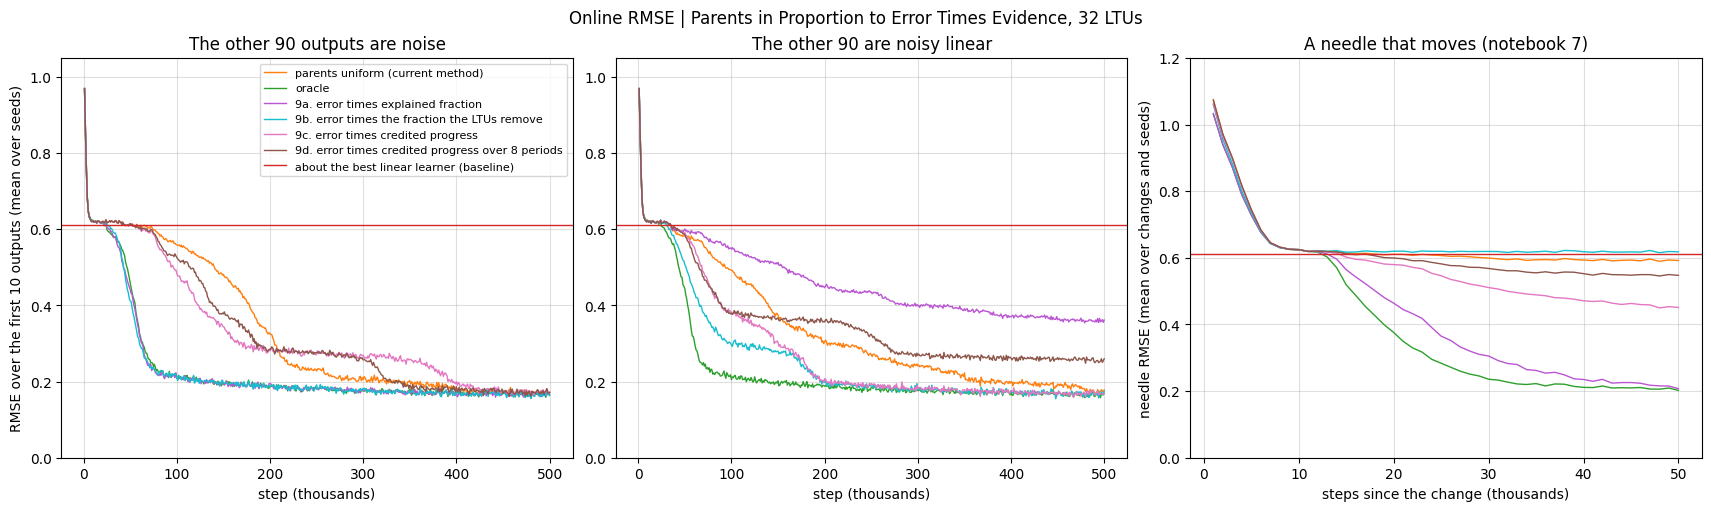

In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
CHANGES = FIRST_CHANGE + CHANGE_EVERY * np.arange(N_CHANGES)
AFTER = CHANGE_EVERY // WINDOW                  # windows from a change to the next
fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout='constrained')
for ax, (kind, changes, title) in zip(axes, PROBLEMS):
    print(title)
    for label, rule, rate, color in RULES:
        rmse, needle, _, _, _ = results[(kind, changes, rule, INIT_STEP_SIZE, rate)]
        if changes:
            after = np.stack([needle[:, c // WINDOW:c // WINDOW + AFTER] for c in CHANGES], 1)
            ax.plot(np.arange(1, AFTER + 1), after.mean((0, 1)), color=color, lw=1, label=label)
            print(f'  {label}: needle RMSE over the {AFTER}k steps after each change {after.mean():.3f} '
                  f'(by seed {np.round(after.mean((1, 2)), 3)})')
        else:
            ax.plot(STEPS / 1000, rmse.mean(0), color=color, lw=1, label=label)
            print(f'  {label}: RMSE averaged over the run {rmse.mean():.3f} (by seed {np.round(rmse.mean(1), 3)})')
    ax.axhline(LINEAR_RMSE, color='tab:red', lw=1, label='about the best linear learner (baseline)')
    ax.set(ylim=(0, 1.2 if changes else 1.05), title=title,
           xlabel='steps since the change (thousands)' if changes else 'step (thousands)')
    ax.grid(alpha=0.4)
axes[0].set_ylabel('RMSE over the first 10 outputs (mean over seeds)')
axes[2].set_ylabel('needle RMSE (mean over changes and seeds)')
axes[0].legend(fontsize=8)
fig.suptitle(f'Online RMSE | Parents in Proportion to Error Times Evidence, {N_LTUS} LTUs')
plt.show()

## Results

RMSE averaged over the run with noise / noisy linear outputs, and the needle's RMSE over the 50k steps after each
change (uniform 0.336 / 0.329 / 0.636, oracle 0.231 / 0.229 / 0.395):
- **9a.** Error times explained fraction: 0.229 / 0.456 / 0.432. At the oracle with noise outputs, close to it on the
  needle, fooled by noisy linear outputs.
- **9b.** Error times the fraction the LTUs remove: 0.229 / 0.258 / 0.648. The best single rule with noisy linear
  outputs, but it never finds a needle: no LTU helps a new needle yet, so its weight is 0, and new LTUs reach it only
  by chance. In a pilot with improvable outputs that have features of their own (notebook 5's problem), it fails the
  same way: 0.489 / 0.553 / 0.554 with noise, linear and noisy linear outputs, against uniform's 0.471 / 0.433 /
  0.449.
- **9c, 9d.** Error times credited progress: 0.330 / 0.277 / 0.572 over one period, 0.329 / 0.351 / 0.614 over 8. Slow
  with noise outputs and on the needle; averaging over more periods does not help.
- No single rule wins everywhere. What tells noisy linear outputs apart is evidence from the LTUs, which a new needle
  does not have yet; what finds a needle is the explained fraction the linear learner provides, which noisy linear
  outputs fool. Of these rules, error times explained fraction is the best overall.

## Details

**9b.** $R_o$ is notebook 3's: the squared error the LTUs remove from output $o$, its error without their part of
the prediction minus with it, averaged over the last search period. $L_o + R_o$ is then its error without them, and
$L_o R_o / (L_o + R_o)$ is its error times the fraction of that the LTUs remove: notebook 4a's form, with the LTUs'
share in place of the network's.

**9c, 9d.** Credited progress is the increase in $R_o$ from one search period to the next; 9d averages it with rate
1/8, the share of LTUs replaced per search step, so it adds no setting of its own.

**The needle** is notebook 7's; its oracle sends every new LTU to the newest needle.

**The rest** is as in notebook 4.